# Trace validation

Checks that `data/traces/simulated_trace.csv` (made by `python -m trace_sim`) has the right schema and
looks like the production traces in the SageServe paper. Run the cells top to bottom.

**What to expect (paper targets)**

| Check | Target |
|---|---|
| IW-F + IW-N share of requests | about 72 %, IW-F the largest tier |
| Lag-24h autocorrelation | IW-F 0.7-0.95, IW-N 0.3-0.8, NIW 0-0.3 |
| Weekend / weekday traffic | IW-F far below 1 (quiet weekends), NIW near flat |
| Regions | East > Central > West, no timezone phase shift |

The periodicity checks need at least 2 simulated days of data (a full week is best).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

TRACE = Path("../../data/traces/simulated_trace.csv")   # relative to this notebook (mlops/trace_sim/)

EXPECTED_COLUMNS = ["request_id", "batch_id", "client_tenant", "request_type", "scenario", "sla",
                    "utility", "regions", "model_type", "workload_type", "application_id",
                    "arrival_timestamp", "batch_size", "prompt_size", "token_size"]

df = pd.read_csv(TRACE, dtype={"regions": str})          # keep "012" as text, not the number 12

# --- schema check (same contract as the ETL) ---
assert list(df.columns) == EXPECTED_COLUMNS, f"unexpected columns: {list(df.columns)}"
assert df.isna().sum().sum() == 0, "null values found"
assert set(df.regions) <= {"012", "021", "102", "120", "201", "210"}, "bad `regions` values"
print("schema OK")

# --- derived columns (the CSV only stores the 15 raw columns) ---
df["tier"] = df["sla"].map({1: "IW-F", 60: "IW-N", 86400: "NIW"})            # tier is encoded in the SLA
df["region"] = df["regions"].str[0].map({"0": "west", "1": "central", "2": "east"})   # first = region served
df["hour"] = (df["arrival_timestamp"] // 3600).astype(int)
df["weekday"] = (df["hour"] // 24) % 7                                        # 0 = Monday
n_hours = df["hour"].max() + 1
print(f"{len(df):,} requests over {n_hours} simulated hours ({n_hours / 24:.1f} days)")

schema OK
931,886 requests over 168 simulated hours (7.0 days)


## 1. Tier share and periodicity

In [2]:
hourly = (df.groupby(["hour", "tier"]).size().unstack(fill_value=0)
            .reindex(range(n_hours), fill_value=0))
weekday = (hourly.index // 24) % 7

rows = []
for tier in ["IW-F", "IW-N", "NIW"]:
    s = hourly[tier]
    rows.append({
        "tier": tier,
        "share %": 100 * s.sum() / len(df),
        "lag-24h autocorr": s.autocorr(24) if n_hours > 48 else float("nan"),
        "weekend/weekday": s[weekday >= 5].mean() / s[weekday < 5].mean() if (weekday >= 5).any() else float("nan"),
    })
summary = pd.DataFrame(rows).set_index("tier").round(2)
print(f"IW-F + IW-N share: {summary.loc[['IW-F', 'IW-N'], 'share %'].sum():.1f} %")
summary

IW-F + IW-N share: 72.3 %


,share %,lag-24h autocorr,weekend/weekday
tier,,,
IW-F,40.55,0.81,0.14
IW-N,31.75,0.71,0.61
NIW,27.70,0.11,0.78


## 2. Request rate over time (compare with paper Fig. 3c)

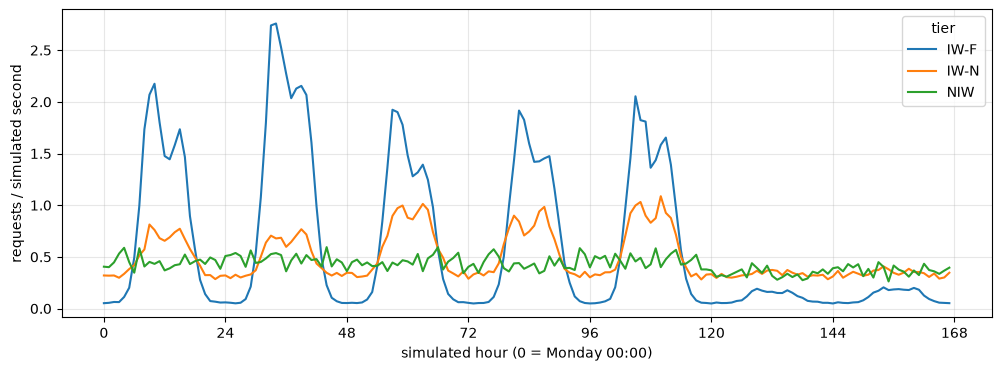

In [3]:
fig, ax = plt.subplots(figsize=(12, 4))
(hourly / 3600).plot(ax=ax)
ax.set_xlabel("simulated hour (0 = Monday 00:00)")
ax.set_ylabel("requests / simulated second")
ax.set_xticks(range(0, n_hours + 1, 24))
ax.grid(alpha=0.3)
plt.show()

## 3. Regions and models (compare with paper Fig. 4)

share of IW-F requests by region and model:


model_type,A,B,C,D
region,,,,
central,0.076,0.210,0.022,0.011
east,0.445,0.065,0.022,0.011
west,0.075,0.047,0.011,0.005


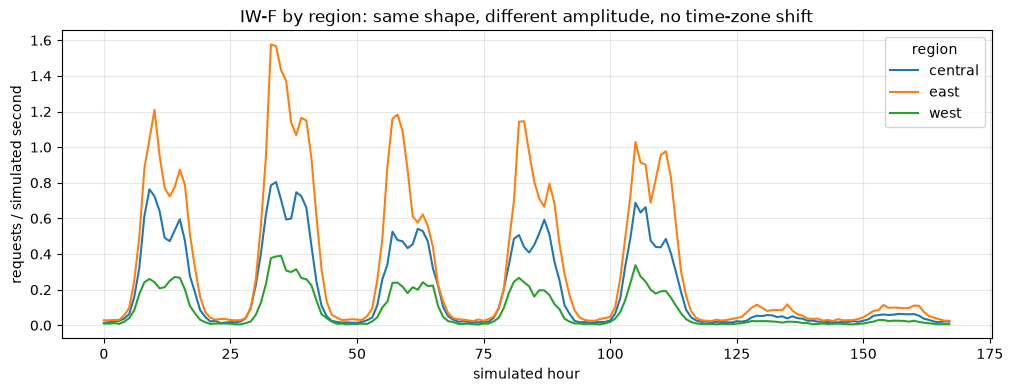

In [4]:
iwf = df[df.tier == "IW-F"]
print("share of IW-F requests by region and model:")
display(pd.crosstab(iwf.region, iwf.model_type, normalize="all").round(3))

by_region = iwf.groupby(["hour", "region"]).size().unstack(fill_value=0).reindex(range(n_hours), fill_value=0)
fig, ax = plt.subplots(figsize=(12, 4))
(by_region / 3600).plot(ax=ax)
ax.set_title("IW-F by region: same shape, different amplitude, no time-zone shift")
ax.set_xlabel("simulated hour"); ax.set_ylabel("requests / simulated second")
ax.grid(alpha=0.3)
plt.show()

## 4. Bursts

Per-minute IW traffic on the busiest day. Random spikes (2-8x, 1-8 minutes) show up as sharp peaks on top of the daily pattern.

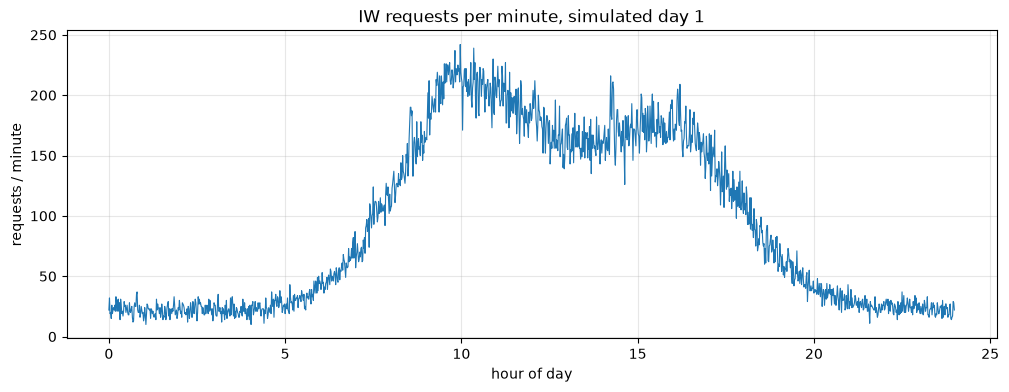

In [5]:
iw = df[df.tier != "NIW"].copy()
iw["minute"] = (iw["arrival_timestamp"] // 60).astype(int)
per_min = iw.groupby("minute").size()
busiest_day = per_min.groupby(per_min.index // 1440).max().idxmax()
day = per_min[(per_min.index // 1440) == busiest_day]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot((day.index - busiest_day * 1440) / 60, day.values, lw=0.8)
ax.set_title(f"IW requests per minute, simulated day {busiest_day}")
ax.set_xlabel("hour of day"); ax.set_ylabel("requests / minute")
ax.grid(alpha=0.3)
plt.show()

## 5. NIW batches

Batch requests arrive together and share a `batch_id`; every batch should have exactly `batch_size` rows.

In [6]:
batches = df[df.batch_id >= 0].groupby("batch_id").agg(rows=("request_id", "size"),
                                                       batch_size=("batch_size", "first"),
                                                       model=("model_type", "first"),
                                                       region=("region", "first"))
print(f"{len(batches)} batches, sizes: {batches.batch_size.value_counts().sort_index().to_dict()}")
assert (batches.rows == batches.batch_size).all(), "some batches have the wrong number of rows"
print("every batch is complete")
batches.head()

83 batches, sizes: {32: 14, 64: 24, 128: 16, 256: 29}
every batch is complete


,rows,batch_size,model,region
batch_id,,,,
0,64,64,C,central
1,256,256,C,east
2,64,64,C,east
3,128,128,C,east
4,32,32,C,east


## 6. Token sizes (compare with paper Fig. 10: prompts mostly > 1k tokens, outputs mostly < 1k)

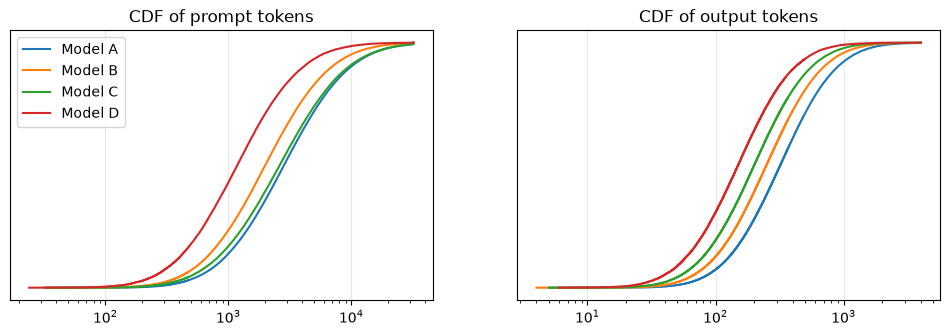

prompts > 1k tokens: 81%   outputs < 1k tokens: 95%


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
import numpy as np

for model, g in df.groupby("model_type"):
    for ax, col in zip(axes, ["prompt_size", "token_size"]):
        x = g[col].sort_values()
        ax.plot(x, np.arange(1, len(x) + 1) / len(x), label=f"Model {model}")
for ax, title in zip(axes, ["prompt tokens", "output tokens"]):
    ax.set_xscale("log"); ax.set_title(f"CDF of {title}"); ax.grid(alpha=0.3)
    ax.set_yticks([])
axes[0].legend()
plt.show()
print(f"prompts > 1k tokens: {(df.prompt_size > 1000).mean():.0%}   outputs < 1k tokens: {(df.token_size < 1000).mean():.0%}")